# Datenanalyse Berliner Denkmalobjekte

In diesem Notebook werden beispielhaft online verfügbare Daten zu Berliner Denkmalobjekten analysiert.
Das Notebook wurde im November 2026 für den Workshops "KI und Denkmalpflege" (Organisation: ICOMOS) angelegt.
Teile des Notebooks wurden mittels der generativen KI M365 Copilot (GPT‑5 Chat Modell) von Microsoft im Modus "Unternehmesdatenschutz" erstellt.

Adrian Leander Pöllinger, Institut für Denkamlpflege und Bauforschung, ETH Zürich, November 2026

# Teil 1: Abfrage des öffentlichen Web Service

## Setup
Zu beginn werden die in der folge benötigten Python Biliotheken installiert

In [1]:
pip install geopandas matplotlib folium owslib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 21.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [owslib]2m1/2 [owslib]
Note: you may need to restart the kernel to use updated packages.


Diese Bibliotheken werden anschliessend geladen

In [2]:
# Geodatenverarbeitung
import geopandas as gpd
import pandas as pd
import numpy as np

# Darstellung
import matplotlib.pyplot as plt

# Karten
import folium

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)

print("Bibliotheken geladen.")

Bibliotheken geladen.


## Berliner Denkmale laden
Nun können die Daten vom WebFeatureService Berlins geladen werden.
Je nach GeoServer-Version kann sich der Layername ändern. Deshalb fragen wir zunächst die verfügbaren Layer ab.

In [3]:
from owslib.wfs import WebFeatureService

WFS_URL = "https://gdi.berlin.de/services/wfs/denkmale"

wfs = WebFeatureService(
    url=WFS_URL,
    version="2.0.0"
)

print("Verfügbare Layer:")
for layer in list(wfs.contents):
    print(layer)

Verfügbare Layer:
denkmale:denkmale


### Gewünschten Layer laden

Der Layer denkmale:denkmale wird geladen und der Inhalt in eine eigene Datenbank (pandas dataframe) namens gdf gespeichert, so dass er in der folge im Notebook verfügbar ist.

In [4]:
url = (
    "https://gdi.berlin.de/services/wfs/denkmale"
    "?SERVICE=WFS"
    "&VERSION=2.0.0"
    "&REQUEST=GetFeature"
    "&TYPENAMES=denkmale:denkmale"
    "&OUTPUTFORMAT=application/json"
)

gdf = gpd.read_file(url)

print(len(gdf))
gdf.head()

9578


,gisid,id,link,typ,geometry
0,BAUD_09010001,09010001,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010001,Baudenkmal,"MULTIPOLYGON (((381106.385 5826097.953, 381106.387 5826097.953, 381116.18 5826099.604, 381116.18 5826099.604, 381117.708 5826099.861, 381117.716 5826099.873, 381115.334 5826114.078, 381112.553 582..."
1,BAUD_09010008,09010008,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010008,Baudenkmal,"MULTIPOLYGON (((395645.763 5814439.908, 395653.397 5814451.938, 395594.851 5814489.052, 395595.733 5814490.445, 395594.888 5814490.981, 395594.006 5814489.588, 395535.432 5814526.717, 395528.691 5..."
2,BAUD_09010009,09010009,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010009,Baudenkmal,"MULTIPOLYGON (((396452.601 5819434.486, 396456.842 5819435.83, 396456.74 5819436.079, 396462.817 5819438.005, 396459.776 5819447.603, 396456.414 5819446.538, 396455.942 5819448.028, 396448.416 581..."
3,BAUD_09010010,09010010,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010010,Baudenkmal,"MULTIPOLYGON (((396492.687 5819338.216, 396499.415 5819340.1, 396497.732 5819345.96, 396498.152 5819346.07, 396495.074 5819355.71, 396493.588 5819355.289, 396487.341 5819353.523, 396487.863 581935..."
4,BAUD_09010012,09010012,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010012,Baudenkmal,"MULTIPOLYGON (((396250.497 5819814.629, 396250.501 5819814.63, 396265.927 5819820.898, 396265.932 5819820.911, 396263.807 5819825.997, 396275.734 5819830.852, 396277.829 5819825.744, 396277.842 58..."


Die Quelle enthält zwei Identifikationsnummern, einen Link zur Denkmaldatenbank Berlins, den Denkmaltyp und die 2D-Geometry des Denkmals.

### Datenanalyse
Die Werte der einzelen Spalten lassen sich nun analysieren. Wir beginnen mit einer Übersicht der Häufigkeit der Denkmaltypen.

In [5]:
gdf["typ"].value_counts()

typ
Baudenkmal       7178
Gesamtanlage     1258
Gartendenkmal     564
Ensemble          511
Bodendenkmal       67
Name: count, dtype: int64

Im nächsten Schritt untersuchen wir die räumliche Verteilung der Denkmaltypen.

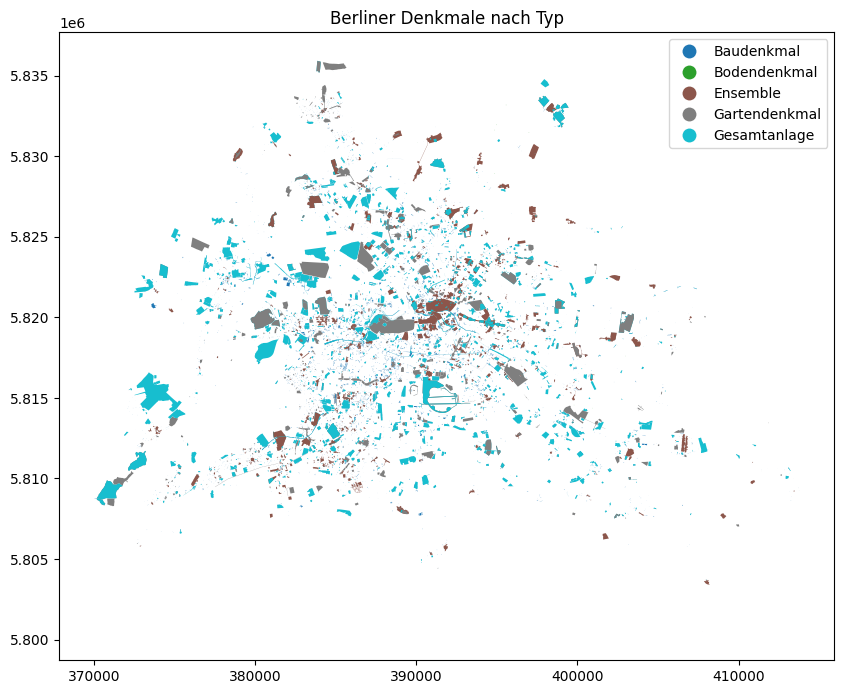

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))

gdf.plot(
    column="typ",
    ax=ax,
    legend=True,
    markersize=2
)

ax.set_title("Berliner Denkmale nach Typ")

plt.show()

Und zum Schluss ordnen wir die Flächen der Denkmäler nach ihrer Größe.

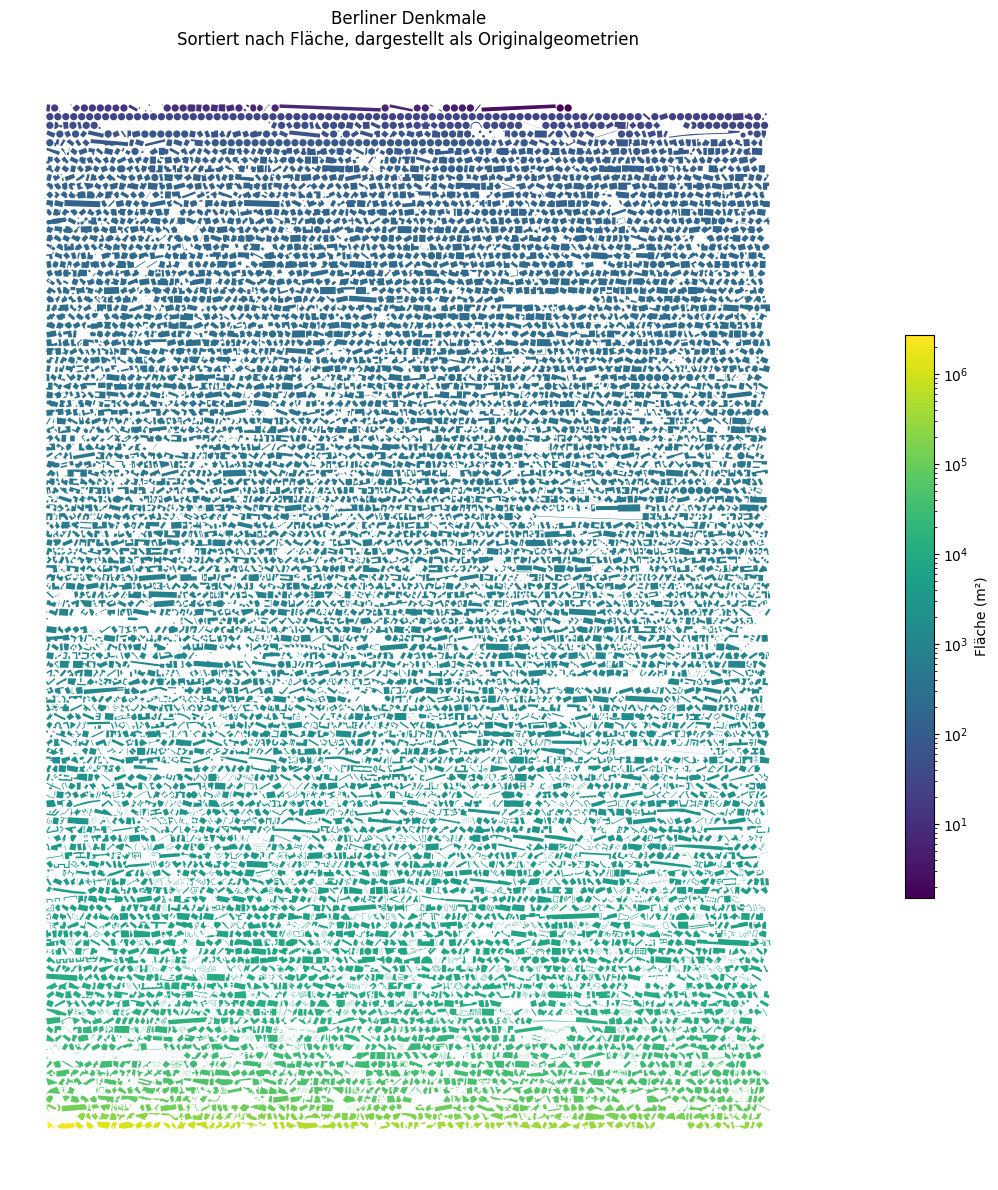

In [ ]:
from shapely import affinity
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt

# --------------------------------------------------
# Parameter
# --------------------------------------------------

ZEILENHOEHE = 100         # Höhe jeder Geometrie nach Skalierung
ZIELBREITE = 10000        # maximale Zeilenbreite
ABSTAND_X = 10
ABSTAND_Y = 20

# --------------------------------------------------
# Flächen berechnen und sortieren
# --------------------------------------------------

gdf_plot = gdf.copy()

gdf_plot["flaeche"] = gdf_plot.geometry.area

gdf_plot = (
    gdf_plot
    .sort_values("flaeche", ascending=False)
    .reset_index(drop=True)
)

# --------------------------------------------------
# Geometrien platzieren
# --------------------------------------------------

patches = []
farben = []

x_cursor = 0
y_cursor = 0

for _, row in gdf_plot.iterrows():

    geom = row.geometry

    minx, miny, maxx, maxy = geom.bounds

    breite = maxx - minx
    hoehe = maxy - miny

    if hoehe == 0:
        continue

    # Alle Geometrien auf dieselbe Höhe skalieren
    faktor = ZEILENHOEHE / hoehe

    geom_skaliert = affinity.scale(
        geom,
        xfact=faktor,
        yfact=faktor,
        origin=(minx, miny)
    )

    minx2, miny2, maxx2, maxy2 = geom_skaliert.bounds

    breite2 = maxx2 - minx2

    # Neue Zeile falls nötig
    if x_cursor + breite2 > ZIELBREITE:

        x_cursor = 0
        y_cursor += ZEILENHOEHE + ABSTAND_Y

    geom_verschoben = affinity.translate(
        geom_skaliert,
        xoff=x_cursor - minx2,
        yoff=y_cursor - miny2
    )

    if geom_verschoben.geom_type == "Polygon":

        patches.append(
            MplPolygon(
                np.asarray(geom_verschoben.exterior.coords),
                closed=True
            )
        )

        farben.append(row.flaeche)

    elif geom_verschoben.geom_type == "MultiPolygon":

        for poly in geom_verschoben.geoms:

            patches.append(
                MplPolygon(
                    np.asarray(poly.exterior.coords),
                    closed=True
                )
            )

            farben.append(row.flaeche)

    x_cursor += breite2 + ABSTAND_X

# --------------------------------------------------
# Darstellung
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(20, 12))

sammlung = PatchCollection(
    patches,
    cmap="viridis",
    norm=LogNorm(
        vmin=gdf_plot["flaeche"].min(),
        vmax=gdf_plot["flaeche"].max()
    ),
    edgecolor="none"
)

sammlung.set_array(np.array(farben))

ax.add_collection(sammlung)

ax.autoscale_view()
ax.set_aspect("equal")

ax.set_title(
    "Berliner Denkmale\nSortiert nach Fläche, dargestellt als verkleinerte Geometrien"
)

ax.axis("off")

fig.colorbar(
    sammlung,
    ax=ax,
    label="Fläche (m²)",
    shrink=0.5
)

plt.tight_layout()
plt.show()

In einem nächsten Schritt könnten weitere Daten aus anderen Quellen dazugeladen werden. Beispielsweise zum Gebäudealter oder geplanten Bauprojekten.